In [1]:
# 필요한 라이브러리 불러오기
import numpy as np              # 넘파이: 숫자 계산
import pandas as pd             # 판다스: 데이터 정리
import yfinance as yf           # 와이파이낸스: 주식 데이터 수집
import matplotlib.pyplot as plt # 맷플롯립: 그래프 출력
from sklearn.preprocessing import MinMaxScaler  # 민맥스 스케일러: 데이터 범위를 0~1로 정규화
from tensorflow.keras.models import Sequential   # 시퀀셜: 모델 층을 순서대로 쌓기
from tensorflow.keras.layers import GRU, Dense   # GRU: 과거 정보 중 필요한 내용을 기억 / Dense: 최종 예측값 계산

# 🍔 LSTM 주방장 대신 GRU 주방장을 불러와서 같은 주가 예측 작업 준비하기

In [2]:
# 1. 데이터 수집
ticker = "AAPL"  # 애플 주식 종목 코드
data = yf.download(ticker, start="2015-01-01", end="2024-01-01")
# 2015년부터 2023년까지 애플 주가 데이터 수집

data = data[['Close']]  # 종가 데이터만 선택

# 🍔 애플 햄버거의 하루 마감 가격만 모아오기

[*********************100%***********************]  1 of 1 completed


In [3]:
# 2. 데이터 전처리
scaler = MinMaxScaler(feature_range=(0, 1))  # 민맥스 스케일러: 데이터를 0~1 사이로 정규화
scaled_data = scaler.fit_transform(data)  # 데이터의 최솟값은 0, 최댓값은 1로 변환

# 🍔 가격이 서로 다른 재료들을 같은 기준으로 맞추기

In [4]:
# GRU 모델에 적합한 데이터셋 생성 함수
def create_dataset(dataset, look_back=60):  # 과거 60일 데이터를 사용하도록 설정
    X, y = [], []  # X: 입력 데이터, y: 정답 데이터

    for i in range(len(dataset) - look_back):  # 전체 데이터에서 60일씩 이동
        X.append(dataset[i:i + look_back, 0])  # 과거 60일 종가를 입력 데이터 X에 저장
        y.append(dataset[i + look_back, 0])  # 그다음 날 종가를 정답 데이터 y에 저장

    return np.array(X), np.array(y)  # 리스트를 넘파이 배열로 변환하여 반환

# 🍔 과거 60일 주문 기록을 보고 다음 날 가격을 예상할 수 있도록 문제지 만들기

In [5]:
# 과거 60일 데이터를 기준으로 학습 데이터 만들기
look_back = 60  # 과거 60일 주가를 보고 다음 날 주가 예측

X, y = create_dataset(scaled_data, look_back)  # 입력 데이터 X와 정답 데이터 y 생성

X = np.reshape(X, (X.shape[0], X.shape[1], 1))  # GRU가 이해할 수 있는 3차원 형태로 변환
# X.shape[0]: 전체 샘플 수
# X.shape[1]: 시퀀스 길이(과거 60일)
# 1: 피처 수(종가 데이터 1개)

# 🍔 과거 60일 주문 기록을 한 묶음으로 만들어 다음 날 가격 예측하기


In [6]:
# 3. GRU 모델 구성
model = Sequential([  # 신경망 층을 순서대로 쌓아 모델 구성

    GRU(50, return_sequences=True, input_shape=(X.shape[1], 1)),
    # 첫 번째 GRU 층: 과거 60일의 주가 패턴 학습
    # 50: 학습에 사용할 뉴런(유닛) 50개
    # return_sequences=True: 학습한 전체 시퀀스를 다음 GRU 층에 전달
    # input_shape: (시퀀스 길이, 피처 수)

    GRU(50),  # 두 번째 GRU 층: 전달받은 정보를 요약하여 학습

    Dense(1)  # 최종 출력층: 다음 날 주가 예측값 1개 출력
])

# 🍔 첫 번째 주방장이 주문 흐름을 살피고,
# 두 번째 주방장이 핵심을 정리한 뒤 최종 가격을 내놓기

c:\Users\human-01\OneDrive\Desktop\Python_AI_Lab\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [7]:
# GRU 모델의 학습 방식 설정
model.compile(
    optimizer='adam',  # 아담: 오차를 줄이도록 가중치를 조정하는 센스 있는 주방장
    loss='mean_squared_error'  # 평균제곱오차: 예측값과 실제값의 차이를 제곱해 평균 계산
)

# 🍔 주방장이 실제 맛과 예상 맛의 차이를 줄이도록 조리법 조정하기

In [8]:
# 4. 모델 학습용 데이터와 테스트용 데이터 분리
train_size = int(len(X) * 0.8)  # 전체 데이터의 80%는 학습용, 20%는 테스트용

X_train, X_test = X[:train_size], X[train_size:]
# X_train: 학습용 문제지 80%
# X_test: 테스트용 문제지 20%

y_train, y_test = y[:train_size], y[train_size:]
# y_train: 학습용 정답지 80%
# y_test: 테스트용 정답지 20%

# 🍔 80%는 연습 문제, 20%는 실전 시험 문제!


In [9]:
# GRU 모델 학습 시작
history = model.fit(
    X_train, y_train,  # 학습용 문제지와 정답지
    epochs=20,         # 전체 학습 데이터를 20번 반복 학습
    batch_size=32,     # 한 번에 32개씩 묶어서 학습
    validation_data=(X_test, y_test),  # 테스트 데이터로 학습 중 성능 확인
    shuffle=False      # 주가의 시간 순서를 유지하고 데이터 섞지 않기
)

# history: 학습 과정에서 기록된 손실값과 검증 손실값 등을 저장
# 🍔 연습 문제를 20회 반복해서 풀고, 시험 문제로 중간 점검하기

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 0.0016 - val_loss: 0.0017
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0058 - val_loss: 0.0033
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0078 - val_loss: 8.0173e-04
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0019 - val_loss: 4.5803e-04
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.3748e-04 - val_loss: 4.6407e-04
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.4023e-04 - val_loss: 4.3684e-04
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1.2247e-04 - val_loss: 3.8995e-04
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 1.1576e-04 - val_loss: 3.5120e-04
Epoch 9/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - loss: 1.1402e-04 - val_loss: 3.2816e-04
Epoch 10/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 1.1541e-04 - val_loss: 3.1308e-04
Epoch 11/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 1.2637e-04 - val_loss: 3.0470e-04

In [10]:
# 5. 주가 예측
predictions = model.predict(X_test)  # 테스트용 문제지를 GRU 모델에 넣어 주가 예측

predictions = scaler.inverse_transform(predictions.reshape(-1, 1))
# reshape(-1, 1): 예측값을 2차원 배열로 변환
# -1: 전체 예측 데이터 개수에 맞춰 행의 수 자동 계산
# 1: 열을 1개로 지정 (주가 데이터 1개)
# inverse_transform: 0~1로 정규화했던 예측값을 실제 주가로 복원

# 🍔 작게 줄여 놓았던 가격을 원래 가격으로 되돌리기

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step


In [11]:
# 실제 주가 복원
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))
# reshape(-1, 1): 실제 주가 데이터를 2차원 배열로 변환
# -1: 전체 데이터 개수에 맞춰 행의 수 자동 계산
# 1: 열을 1개로 지정 (실제 주가 데이터 1개)
# inverse_transform: 0~1로 정규화했던 실제 주가를 원래 가격으로 복원

# 🍔 시험 정답지에 있는 축소된 가격을 원래 가격으로 되돌리기

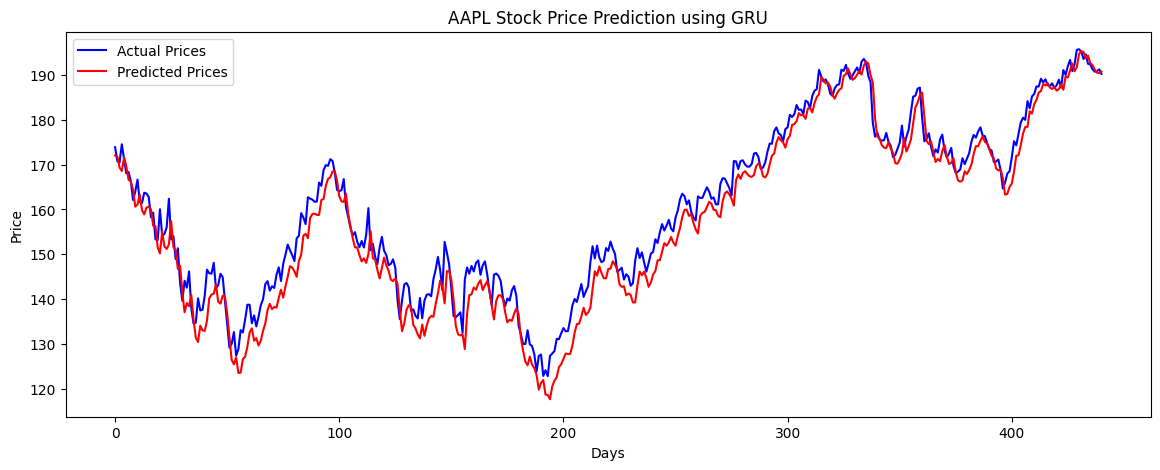

In [12]:
# 6. 실제 주가와 GRU 예측 주가 시각화
plt.figure(figsize=(14, 5))  # 그래프 크기 설정 (가로 14, 세로 5)

plt.plot(actual_prices, label="Actual Prices", color='blue')
# 실제 주가를 파란색 선으로 표시

plt.plot(predictions, label="Predicted Prices", color='red')
# GRU 모델이 예측한 주가를 빨간색 선으로 표시

plt.title(f'{ticker} Stock Price Prediction using GRU')
# 그래프 제목: GRU를 이용한 애플 주가 예측

plt.xlabel('Days')  # X축: 날짜의 흐름
plt.ylabel('Price')  # Y축: 주가
plt.legend()  # 실제 주가와 예측 주가의 범례 표시
plt.show()  # 그래프 화면에 출력

# 🍔 실제 가격표(파란색)와 GRU 요리사가 예상한 가격표(빨간색) 비교하기